# 2. Why rescoring stops helping

The model proposes 12 candidate transcripts per clip. Minimum Bayes risk (MBR) picks the candidate the others agree
with most; the oracle is the best candidate in hindsight. If MBR does not beat greedy decoding, we need to know why
before trying anything else.

In [1]:
from nbutil import *
import pandas as pd

## Choosing among 12 candidates, against greedy decoding (DL Sprint eval)
B minus A in WER points, paired cluster bootstrap.

In [2]:
pd.DataFrame({sel: paired(f"eval_sampled_tugstugi_{sel}_vs_greedy") for sel in ("rank0", "mbr", "oracle")}).T.rename(
    index={"rank0": "first candidate", "mbr": "MBR", "oracle": "best candidate (oracle)"})

,A,B,B - A,95% CI,significant
first candidate,22.71,25.85,3.15,"[+2.85, +3.41]",True
MBR,22.71,22.84,0.14,"[-0.11, +0.35]",False
best candidate (oracle),22.71,18.59,-4.12,"[-4.50, -3.80]",True


MBR ties with greedy decoding although a perfect selector would gain about 4 points. The ceilings show how far selection could go:

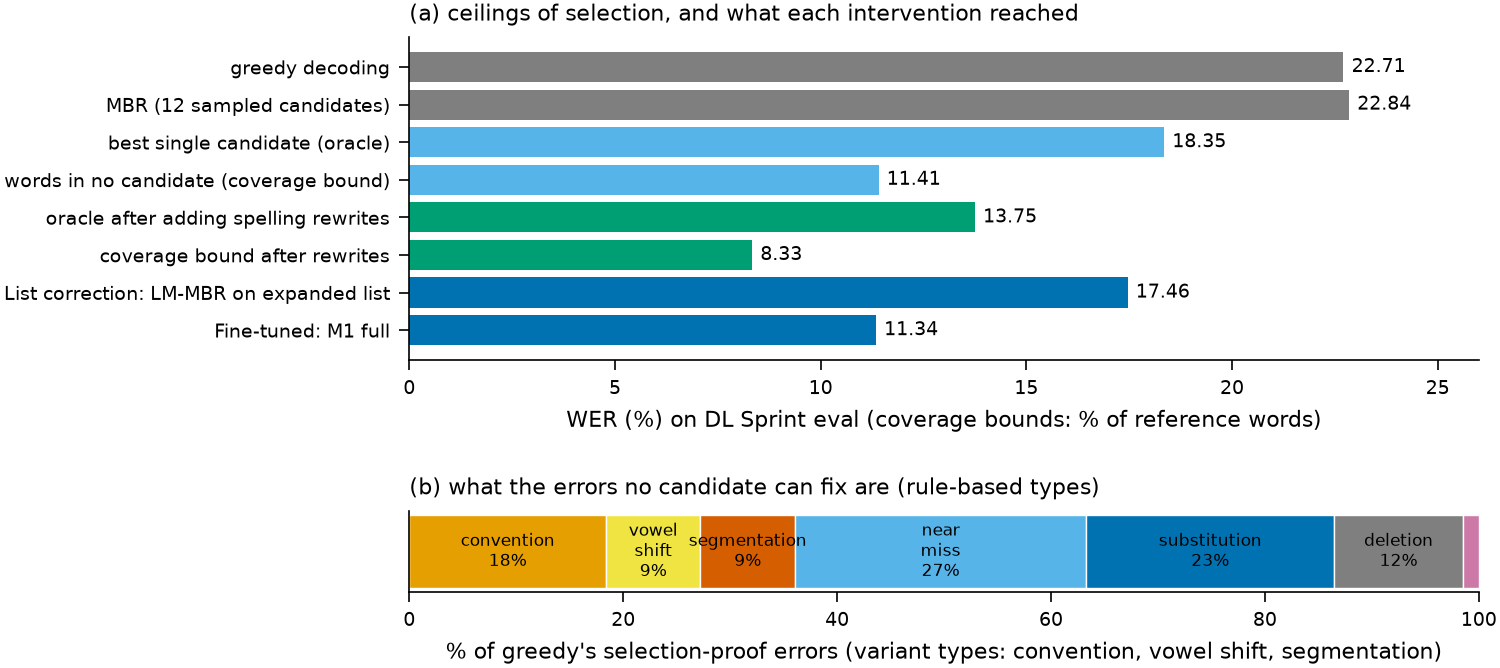

,item,value,kind
0,greedy decoding,22.707000,system
1,MBR (12 sampled candidates),22.844479,system
2,best single candidate (oracle),18.348000,bound
3,words in no candidate (coverage bound),11.406000,bound
4,oracle after adding spelling rewrites,13.748000,bound expanded
5,coverage bound after rewrites,8.332000,bound expanded
6,List correction: LM-MBR on expanded list,17.461000,achieved
7,Fine-tuned: M1 full,11.343092,achieved


In [3]:
figure("f8_ceilings"); figure_data("f8_ceilings").head(8)

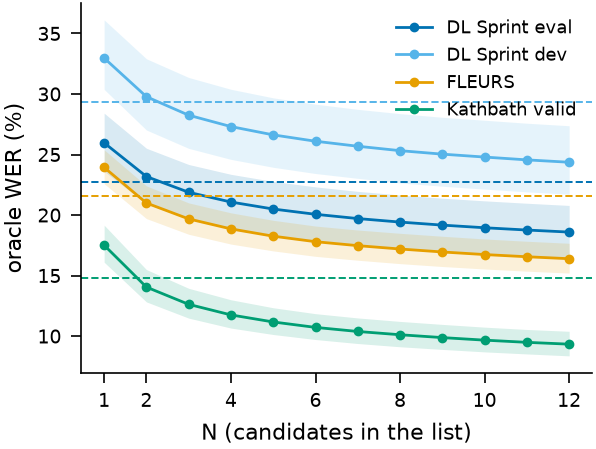

In [4]:
figure("f9_oracle_vs_n", 450)

## What the candidates agree on
For each reference word, count how many of the 12 candidates contain it. MBR fixes an error only when most candidates
already have the right word; most errors are in no candidate at all.

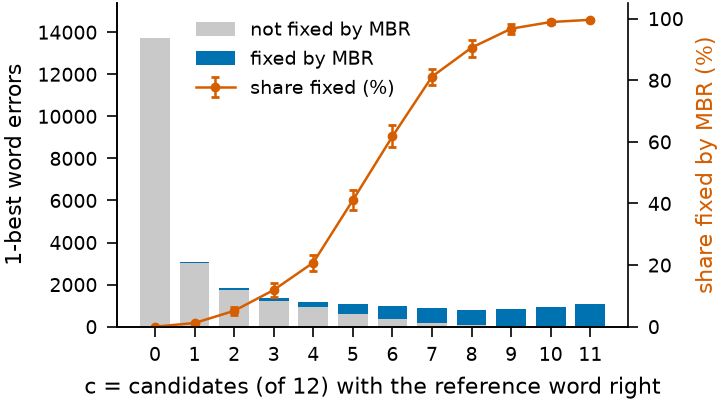

In [5]:
figure("f2_mbr_fix_by_agreement", 560)

A large share of the remaining errors are the same word in another spelling or dialect form, and those are exactly the errors all candidates share:

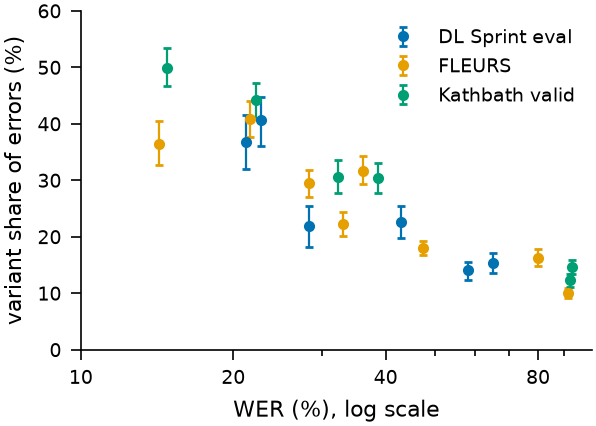

In [6]:
figure("f3_variant_share_by_model", 450)

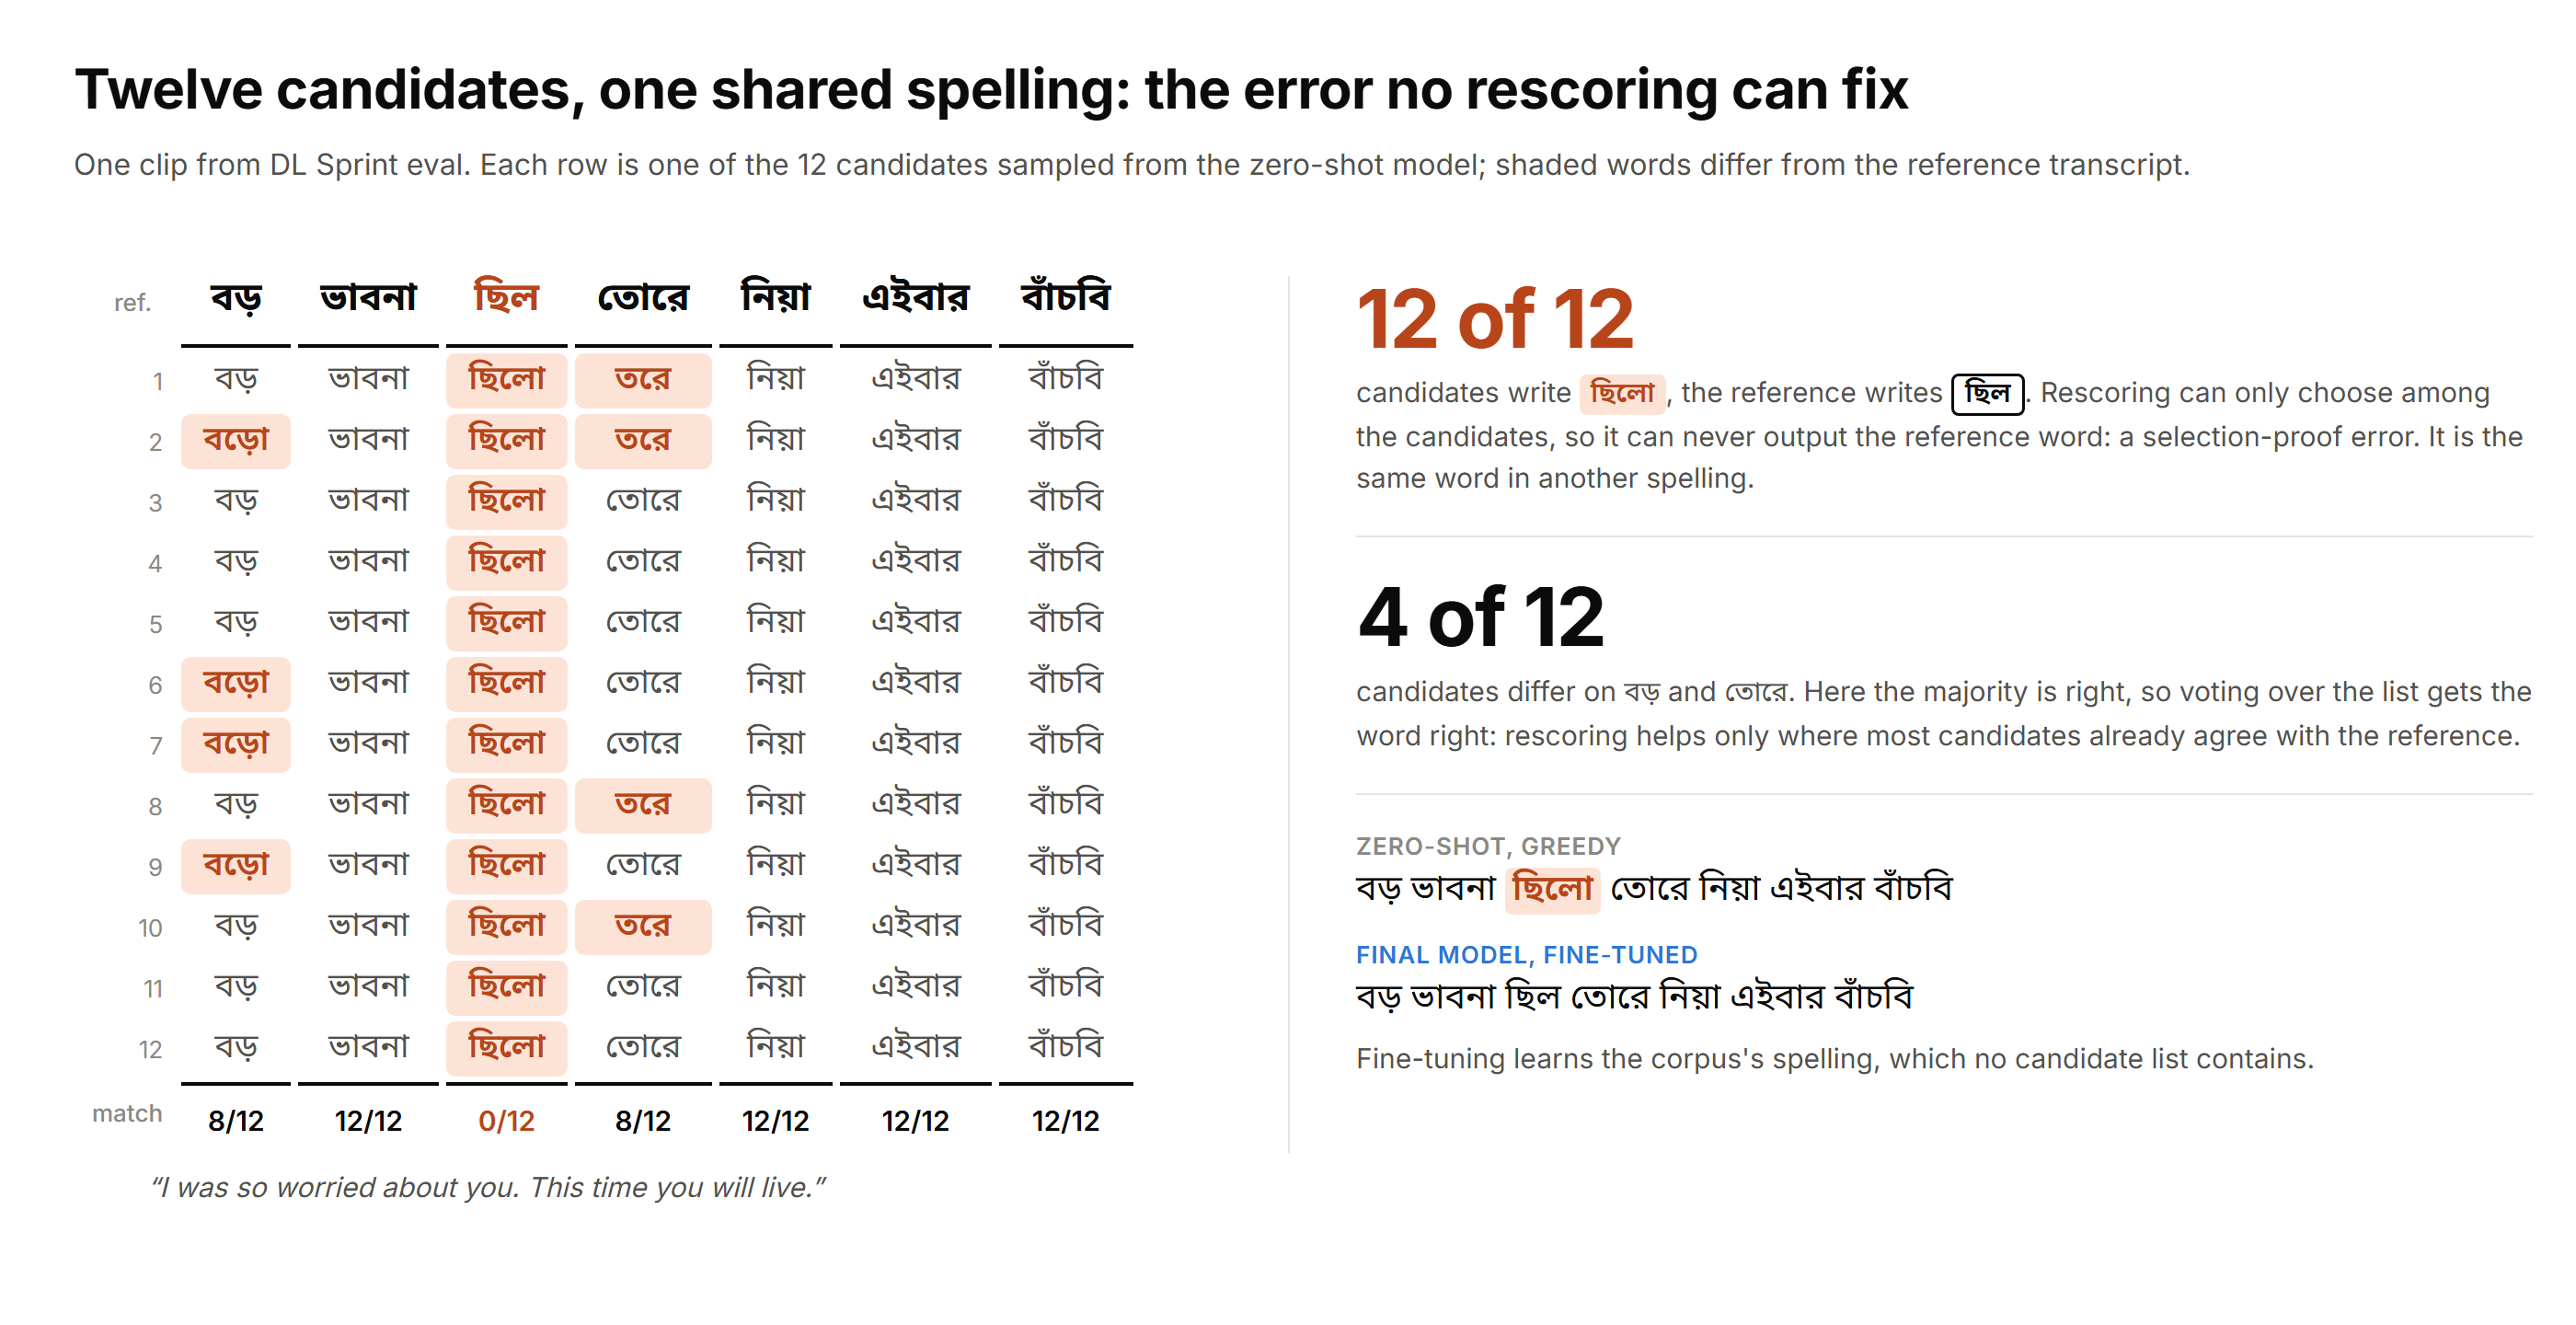

In [7]:
figure("f1_example")

In [8]:
record("results/compare/eval_sampled_tugstugi_mbr_vs_greedy.run_info.json")

**Run record** `results/compare/eval_sampled_tugstugi_mbr_vs_greedy.run_info.json`  
`python.exe analysis/paired_compare.py --a results/zeroshot/splits_fa-eval/bengaliAI__tugstugi_bengaliai-regional-asr_whisper-medium/predictions.jsonl --b data/nbest_fa/eval_sampled.jsonl:mbr --name eval_sampled_tugstugi_mbr_vs_greedy`  
commit `4ca76bd678` · started 2026-10-09T00:31:59 · 0.7 s · torch 2.13.0+cu126, transformers 5.15.0, GPU NVIDIA GeForce RTX 3060

**Next:** a better voter cannot fix a spelling the whole list shares. Either the right spelling has to enter the list
(notebook 3, no retraining) or the model has to learn it (notebook 4).